In [2]:
# dataset: https://github.com/mwaskom/seaborn-data/blob/master/exercise.csv

import pandas as pd

# Open a file

data = pd.read_csv(
    "exercise.csv",
    sep=",",
    header="infer",
    index_col=0,
    encoding="utf-8"
)

# In jupyter notebook, dataframes are prettier without using print()
data

,id,diet,pulse,time,kind
0,1,low fat,85,1 min,rest
1,1,low fat,85,15 min,rest
2,1,low fat,88,30 min,rest
3,2,low fat,90,1 min,rest
4,2,low fat,92,15 min,rest
...,...,...,...,...,...
85,29,no fat,135,15 min,running
86,29,no fat,130,30 min,running
87,30,no fat,99,1 min,running
88,30,no fat,111,15 min,running


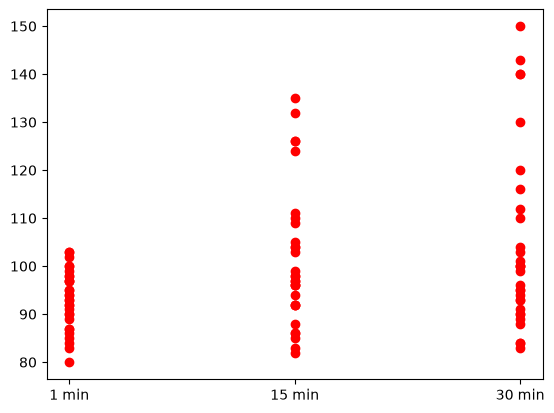

In [4]:
# First exercise: plot the pulse of each entry in data according to time

import matplotlib.pyplot as plt 

pulse = [int(i) for i in data["pulse"]] # convert values to int for the plot
time = data["time"]

plt.scatter(time, pulse, color="red")

<StringArray>
['rest', 'walking', 'running']
Length: 3, dtype: str


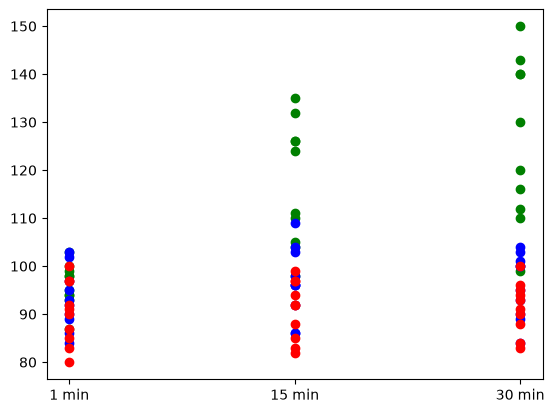

In [5]:
# Issue: we don't make a difference between individual at rest and the ones running and walking
# Solution: do one scatter plot per category in "kind"

# Check the values of the "kind" column
print(data["kind"].unique())

pulse_running = [pulse[i] for i in range(len(pulse)) if data["kind"][i] == "running"]
time_running = [time[i] for i in range(len(time)) if data["kind"][i] == "running"]

pulse_walking = [pulse[i] for i in range(len(pulse)) if data["kind"][i] == "walking"]
time_walking = [time[i] for i in range(len(time)) if data["kind"][i] == "walking"]

pulse_rest = [pulse[i] for i in range(len(pulse)) if data["kind"][i] == "rest"]
time_rest = [time[i] for i in range(len(time)) if data["kind"][i] == "rest"]

plt.scatter(time_running, pulse_running, color="green")
plt.scatter(time_walking, pulse_walking, color="blue")
plt.scatter(time_rest, pulse_rest, color="red")

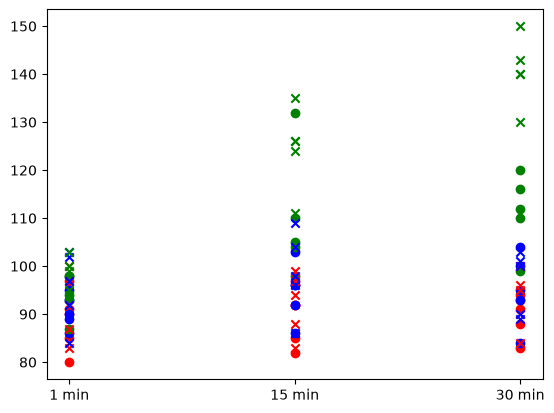

In [6]:
# What if we also want to report data according to the diet of each individual ?
# Solution: add more scatter plots !

# We will also proceed differently, there are multiple ways of obtaining the same result !

# We create a big dictionary to save everything, we could have done this step in multiple ways.
# For instance, it is possible to adapt a pandas.dataframe to a dictionary with a function call...

dict_values = {
    "low fat": {
        "rest": {
            "pulse": [],
            "time": []
            },
        "walking":{
            "pulse": [],
            "time": []
            },
        "running":{
            "pulse": [],
            "time": []
            }
    },
    "no fat": {
        "rest": {
            "pulse": [],
            "time": []
            },
        "walking":{
            "pulse": [],
            "time": []
            },
        "running": {
            "pulse": [],
            "time": []
            }
    }
}

# We populate our dictionary

for i in range(len(data)):

    diet = data["diet"][i]
    kind = data["kind"][i]

    dict_values[diet][kind]["pulse"].append(data["pulse"][i])
    dict_values[diet][kind]["time"].append(data["time"][i])

# Finally, we create each scatter plot

for key,values in dict_values.items():

    marker_shape = "o"
    if key == "no fat":
        marker_shape = "x"

    for k,v in values.items():

        color = "red"
        if k == "running":
            color = "green"
        elif k == "walking":
            color = "blue"

        plt.scatter(v["time"], v["pulse"], color=color, marker=marker_shape)

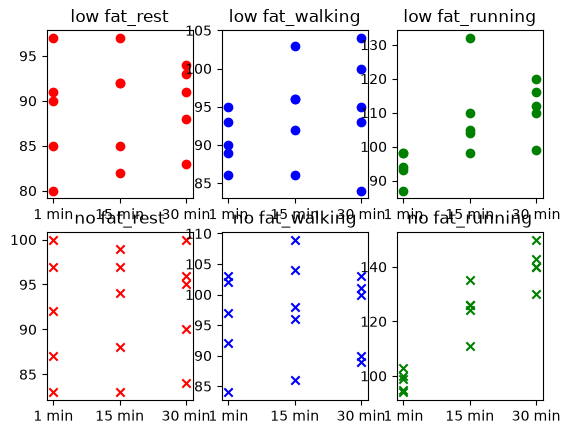

In [7]:
# Issue: the graph is now quite hard to read...
# Solution: create one graph for each scatter plot and show them side-by-side

# we already have our dictionary, lets use it !
# Moreover, we know we want 6 subplots, since we made 6 scatter plot earlier

# Lets initiate a graph containing multiple graphs in it
fig, axs = plt.subplots(2, 3) # number of row * number of columns

# Note: the graph should still be hard to read.
# Try to add the following parameters after your first observations: sharey=True, sharex=True

x = 0
y = 0

for key,values in dict_values.items():

    marker_shape = "o"
    if key == "no fat":
        marker_shape = "x"

    for k,v in values.items():

        color = "red"
        if k == "running":
            color = "green"
        elif k == "walking":
            color = "blue"

        axs[y,x].scatter(v["time"], v["pulse"], color=color, marker=marker_shape)
        axs[y,x].set_title(f"{key}_{k}")

        x += 1
    y += 1
    x = 0